# E1b — Context-budget fixes for the starter agent (31B)

**Why.** E1/E2 found 93% of starter failures are context exhaustion: vLLM rejects a request
when prompt + `max_output_tokens` (16384) > 32768, so the usable prompt is 16k, and runs die
while still localizing. This ablation measures what cheap fixes recover.

| Arm | Change (vs parent) | Submittable |
|---|---|---|
| A | starter as-is | yes |
| B | A + `max_output_tokens` = thinking + 4096 (usable prompt 16k → 24k) | yes |
| C | B + prompt guidance: grep then small reads; scratch via `run_command` in `/tmp` | yes |
| D | B + fresh-context retry on the same workspace after a context death | diagnostic |
| E | B + Gemma's recommended sampling (T 1.0, top_p 0.95, top_k 64); added 2026-09-26 | yes |

**Pre-registered comparisons** (paired on the same task × seed, 95% bootstrap CI stratified
by repo, exact McNemar): B−A, C−B, D−B, C−A. A fix counts only if its CI excludes 0.

## 0 · Parameters

In [1]:
CONFIG_OVERRIDES: dict = {}

In [2]:
# Parameters
CONFIG_OVERRIDES = "{\"params.arms\": [\"F\"], \"params.seeds\": [0], \"params.label\": \"armF_v019\", \"params.thinking_translation\": \"budget\", \"params.reuse_arm_a\": \"<repo>/experiments/E1_starter_baseline/runs/20260925T115751Z-fa203996-b8e7/artifacts/swebox/t6min\", \"params.reuse\": {\"B\": \"<repo>/experiments/E1b_context_fixes/runs/20260925T210110Z-31559935-5542/artifacts/swebox/arm_B\"}, \"params.comparisons\": [[\"B\", \"F\"], [\"A\", \"F\"]]}"


## 1 · Setup & provenance

In [3]:
from pathlib import Path

import polars as pl
from IPython.display import Markdown, display
from src.arms import context_retries, make_arm
from src.params import Params

from rbcore import RunContext, load_config, plotting, stats
from rbcore.paths import data_root
from swebox import sandbox as sb
from swebox.analysis import load_results
from swebox.evaluate import EvalSpec, evaluate
from swebox.submission import ServingTarget
from swebox.tasks import load_tasks, select
from swebox.tools import Budget

EXP_DIR = Path.cwd()
cfg = load_config(EXP_DIR / "config.yaml", Params, CONFIG_OVERRIDES)
P = cfg.params
plotting.use_style()
tasks = select(load_tasks(), P.subset)
task_ids = {t.instance_id for t in tasks}
limits = sb.Limits(cfg.sandbox.mem_gib or 8, cfg.sandbox.cpus or 4)
reused = {**({"A": P.reuse_arm_a} if P.reuse_arm_a else {}), **P.reuse}
run_arms = [a for a in P.arms if a not in reused] + ([] if "A" in reused else ["A"])
display(
    Markdown(
        f"config `{cfg.hash()}` · {len(tasks)} tasks × seeds {P.seeds} · running arms "
        f"{run_arms} · reused {reused or 'none'} · "
        f"**{len(run_arms) * len(tasks) * len(P.seeds)} sessions**"
    )
)

<repo>/harness/src/swebox/agent_runner.py:44: UserWarning: [EXPERIMENTAL] EventsCompactionConfig: This feature is experimental and may change or be removed in future versions without notice. It may introduce breaking changes at any time.
  COMPACTION = EventsCompactionConfig(
<repo>/.venv/lib/python3.12/site-packages/google/adk/features/_feature_decorator.py:71: UserWarning: [EXPERIMENTAL] feature FeatureName.AGENT_CONFIG is enabled.
  check_feature_enabled()


config `f77eec3d1ff4` · 40 tasks × seeds [0] · running arms ['F'] · reused {'A': '<repo>/experiments/E1_starter_baseline/runs/20260925T115751Z-fa203996-b8e7/artifacts/swebox/t6min', 'B': '<repo>/experiments/E1b_context_fixes/runs/20260925T210110Z-31559935-5542/artifacts/swebox/arm_B'} · **40 sessions**

## 2 · Preflight
The starter's LoRA adapters must be served (all arms keep them, so only the named factor
changes): `bash infra/vllm/serve_submission.sh`.

In [4]:
import httpx

served = {
    m["id"]
    for m in httpx.get(f"{cfg.serving.base_url}/v1/models", timeout=5)
    .raise_for_status()
    .json()["data"]
}
if any(a != "F" for a in run_arms):  # arm F drops the adapters, so it needs none served
    assert {"main_lora", "tool_lora"} <= served, f"adapters not served: {served}"
reuse: dict[str, pl.DataFrame] = {}
for arm, src_dir in reused.items():
    reuse[arm] = load_results(Path(src_dir)).filter(
        pl.col("instance_id").is_in(task_ids) & pl.col("seed").is_in(P.seeds)
    )
    missing = len(task_ids) * len(P.seeds) - reuse[arm].height
    display(Markdown(f"reused arm {arm} rows: {reuse[arm].height} (missing {missing})"))
    assert missing == 0, f"reused arm {arm} lacks some (task, seed) pairs; run it instead"
dc = sb.client()
dc.ping()

reused arm A rows: 40 (missing 0)

reused arm B rows: 40 (missing 0)

True

## 3 · Open the run

In [5]:
run = RunContext(cfg, exp_dir=EXP_DIR).start()  # closed in section 8 with run.finish()
out_root = Path(P.results_dir) if P.results_dir else run.artifacts / "swebox"
run.event("results_dir", path=str(out_root), resumed=P.results_dir is not None)
print(run.dir)

2026-09-26T23:42:44.911763Z [warning  ] run.sandbox_not_eval_faithful  [rbcore.run] experiment=E1b_context_fixes note='fine for development; headline numbers need profile=eval' profile=dev run_id=20260926T234243Z-f77eec3d-d931


[codecarbon WARNING @ 23:42:46] Multiple instances of codecarbon are allowed to run at the same time.


<repo>/experiments/E1b_context_fixes/runs/20260926T234243Z-f77eec3d-d931


## 4 · Run the arms
Resumable: finished (task, seed) pairs are skipped per arm.

In [6]:
base = data_root() / P.base_submission
for arm in run_arms:
    sub = make_arm(base, run.artifacts / "submissions" / arm, arm, P.output_reserve)
    spec = EvalSpec(
        submission=sub,
        limits=limits,
        budget=Budget(
            time_minutes=P.time_minutes, context_retries=context_retries(arm, P.d_context_retries)
        ),
        target=ServingTarget(
            api_base=f"{cfg.serving.base_url}/v1",
            served_model=cfg.serving.model,
            thinking_translation=P.thinking_translation,
        ),
        seeds=tuple(P.seeds),
        concurrency=P.concurrency,
        tag=f"arm_{arm}",
    )
    with run.phase("arm", arm=arm):
        rows = await evaluate(tasks, spec, out_root / f"arm_{arm}", run=run)
    rate = sum(r["resolved"] for r in rows) / len(rows)
    run.log_metrics({f"resolved_arm_{arm}": rate})
    print(arm, f"{rate:.3f}", len(rows))

<repo>/.venv/lib/python3.12/site-packages/google/adk/models/llm_request.py:298: UserWarning: [EXPERIMENTAL] feature FeatureName.JSON_SCHEMA_FOR_FUNC_DECL is enabled.
  declaration = tool._get_declaration()
2026-09-26T23:42:50.099636Z [error    ] Node execution failed with exception [google_adk.google.adk.workflow._node_runner] experiment=E1b_context_fixes run_id=20260926T234243Z-f77eec3d-d931
Traceback (most recent call last):
  File "<repo>/.venv/lib/python3.12/site-packages/litellm/llms/openai/openai.py", line 929, in acompletion
    headers, response = await self.make_openai_chat_completion_request(
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<repo>/.venv/lib/python3.12/site-packages/litellm/litellm_core_utils/logging_utils.py", line 297, in async_wrapper
    result = await func(*args, **kwargs)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<repo>/.venv/lib/python3.12/site-packages/litellm/llms/openai/openai.py", line 460, in make_openai_chat_c

2026-09-26T23:42:50.155757Z [error    ] Node execution failed with exception [google_adk.google.adk.workflow._node_runner] experiment=E1b_context_fixes run_id=20260926T234243Z-f77eec3d-d931
Traceback (most recent call last):
  File "<repo>/.venv/lib/python3.12/site-packages/litellm/llms/openai/openai.py", line 929, in acompletion
    headers, response = await self.make_openai_chat_completion_request(
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<repo>/.venv/lib/python3.12/site-packages/litellm/litellm_core_utils/logging_utils.py", line 297, in async_wrapper
    result = await func(*args, **kwargs)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<repo>/.venv/lib/python3.12/site-packages/litellm/llms/openai/openai.py", line 460, in make_openai_chat_completion_request
    raise e
  File "<repo>/.venv/lib/python3.12/site-packages/litellm/llms/openai/openai.py", line 437, in make_openai_chat_completion_request
    await openai_aclient.chat.completions.wit

2026-09-26T23:42:50.204726Z [error    ] Root node swe_baseline_agent failed. [google_adk.google.adk.runners] experiment=E1b_context_fixes run_id=20260926T234243Z-f77eec3d-d931
Traceback (most recent call last):
  File "<repo>/.venv/lib/python3.12/site-packages/google/adk/workflow/_node_runner_utils.py", line 237, in _drive_root_node
    await root_ctx._run_node_internal(  # pylint: disable=protected-access
  File "<repo>/.venv/lib/python3.12/site-packages/google/adk/agents/context.py", line 604, in _run_node_internal
    raise DynamicNodeFailError(
google.adk.workflow._errors.DynamicNodeFailError: Dynamic node swe_baseline_agent failed

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "<repo>/.venv/lib/python3.12/site-packages/google/adk/runners.py", line 824, in _cleanup_root_task
    await task
  File "<repo>/.venv/lib/python3.12/site-packages/google/adk/workflow/_node_runner_utils.py", line 246, in _drive_root_node
    ra

2026-09-26T23:42:50.250451Z [warning  ] agent.error                    [swebox.agent_runner] error='litellm.BadRequestError: OpenAIException - thinking_token_budget is set but reasoning_config is not configured. Please set --reasoning-config to use thinking_token_budget. LiteLLM Retried: 5 times' experiment=E1b_context_fixes run_id=20260926T234243Z-f77eec3d-d931 task=fastapi_11355


2026-09-26T23:42:50.251169Z [error    ] Root node swe_baseline_agent failed. [google_adk.google.adk.runners] experiment=E1b_context_fixes run_id=20260926T234243Z-f77eec3d-d931
Traceback (most recent call last):
  File "<repo>/.venv/lib/python3.12/site-packages/google/adk/workflow/_node_runner_utils.py", line 237, in _drive_root_node
    await root_ctx._run_node_internal(  # pylint: disable=protected-access
  File "<repo>/.venv/lib/python3.12/site-packages/google/adk/agents/context.py", line 604, in _run_node_internal
    raise DynamicNodeFailError(
google.adk.workflow._errors.DynamicNodeFailError: Dynamic node swe_baseline_agent failed

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "<repo>/.venv/lib/python3.12/site-packages/google/adk/runners.py", line 824, in _cleanup_root_task
    await task
  File "<repo>/.venv/lib/python3.12/site-packages/google/adk/workflow/_node_runner_utils.py", line 246, in _drive_root_node
    ra

2026-09-26T23:42:50.298468Z [warning  ] agent.error                    [swebox.agent_runner] error='litellm.BadRequestError: OpenAIException - thinking_token_budget is set but reasoning_config is not configured. Please set --reasoning-config to use thinking_token_budget. LiteLLM Retried: 5 times' experiment=E1b_context_fixes run_id=20260926T234243Z-f77eec3d-d931 task=fastapi_12942


... (111 outputs left out)

2026-09-26T23:43:20.216390Z [error    ] Node execution failed with exception [google_adk.google.adk.workflow._node_runner] experiment=E1b_context_fixes run_id=20260926T234243Z-f77eec3d-d931
Traceback (most recent call last):
  File "<repo>/.venv/lib/python3.12/site-packages/litellm/llms/openai/openai.py", line 929, in acompletion
    headers, response = await self.make_openai_chat_completion_request(
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<repo>/.venv/lib/python3.12/site-packages/litellm/litellm_core_utils/logging_utils.py", line 297, in async_wrapper
    result = await func(*args, **kwargs)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<repo>/.venv/lib/python3.12/site-packages/litellm/llms/openai/openai.py", line 460, in make_openai_chat_completion_request
    raise e
  File "<repo>/.venv/lib/python3.12/site-packages/litellm/llms/openai/openai.py", line 437, in make_openai_chat_completion_request
    await openai_aclient.chat.completions.wit

2026-09-26T23:43:20.269338Z [error    ] Root node swe_baseline_agent failed. [google_adk.google.adk.runners] experiment=E1b_context_fixes run_id=20260926T234243Z-f77eec3d-d931
Traceback (most recent call last):
  File "<repo>/.venv/lib/python3.12/site-packages/google/adk/workflow/_node_runner_utils.py", line 237, in _drive_root_node
    await root_ctx._run_node_internal(  # pylint: disable=protected-access
  File "<repo>/.venv/lib/python3.12/site-packages/google/adk/agents/context.py", line 604, in _run_node_internal
    raise DynamicNodeFailError(
google.adk.workflow._errors.DynamicNodeFailError: Dynamic node swe_baseline_agent failed

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "<repo>/.venv/lib/python3.12/site-packages/google/adk/runners.py", line 824, in _cleanup_root_task
    await task
  File "<repo>/.venv/lib/python3.12/site-packages/google/adk/workflow/_node_runner_utils.py", line 246, in _drive_root_node
    ra

2026-09-26T23:43:20.314145Z [warning  ] agent.error                    [swebox.agent_runner] error='litellm.BadRequestError: OpenAIException - thinking_token_budget is set but reasoning_config is not configured. Please set --reasoning-config to use thinking_token_budget. LiteLLM Retried: 5 times' experiment=E1b_context_fixes run_id=20260926T234243Z-f77eec3d-d931 task=rich_4076


F 0.000 40


## 5 · Ingest

In [7]:
frames = [
    load_results(out_root / f"arm_{a}").with_columns(pl.lit(a).alias("arm"))
    for a in run_arms
    if (out_root / f"arm_{a}").exists()
]
frames += [df.with_columns(pl.lit(arm).alias("arm")) for arm, df in reuse.items()]
results = pl.concat(frames, how="diagonal_relaxed").with_columns(
    pl.col("agent_error").str.contains("ContextWindow").fill_null(False).alias("context_death")
)
results.write_parquet(run.dir / "results.parquet")
summary = (
    results.group_by("arm")
    .agg(
        pl.len().alias("n"),
        pl.col("resolved").mean().alias("resolved"),
        pl.col("context_death").mean().alias("context_death"),
        pl.col("submitted").mean().alias("submitted"),
        pl.col("agent_seconds").median().alias("median_s"),
        pl.col("prompt_tokens").mean().alias("mean_prompt_tokens"),
        pl.col("context_retries").fill_null(0).mean().alias("mean_retries"),
    )
    .sort("arm")
)
display(summary)

arm,n,resolved,context_death,submitted,median_s,mean_prompt_tokens,mean_retries
str,u32,f64,f64,f64,f64,f64,f64
"""A""",40,0.2,0.7,0.25,124.38,159976.625,0.0
"""B""",40,0.3,0.225,0.525,212.745,267290.675,0.0
"""F""",40,0.0,0.0,0.0,0.17,0.0,0.0


## 6 · Pre-registered comparisons

In [8]:
rows = []
for a, b in P.comparisons:
    left = results.filter(pl.col("arm") == a).select(
        "instance_id", "seed", "repo", pl.col("resolved").alias("x")
    )
    right = results.filter(pl.col("arm") == b).select(
        "instance_id", "seed", pl.col("resolved").alias("y")
    )
    pair = left.join(right, on=["instance_id", "seed"])
    if pair.is_empty():
        continue
    d = stats.paired_diff(
        pair["x"].cast(int), pair["y"].cast(int), strata=pair["repo"], seed=cfg.seed
    )
    mc = stats.mcnemar_exact(pair["x"], pair["y"])
    rows.append(
        {
            "comparison": f"{b} - {a}",
            "rate_a": pair["x"].mean(),
            "rate_b": pair["y"].mean(),
            "diff": d.point,
            "lo": d.lo,
            "hi": d.hi,
            "n": d.n,
            "only_a": mc.only_a,
            "only_b": mc.only_b,
            "p_mcnemar": mc.p_value,
            "significant": d.lo > 0 or d.hi < 0,
        }
    )
comparisons = pl.DataFrame(rows)
run.event("comparisons", rows=comparisons.to_dicts())
display(comparisons)

comparison,rate_a,rate_b,diff,lo,hi,n,only_a,only_b,p_mcnemar,significant
str,f64,f64,f64,f64,f64,i64,i64,i64,f64,bool
"""F - B""",0.3,0.0,-0.3,-0.45,-0.175,40,12,0,0.000488,true
"""F - A""",0.2,0.0,-0.2,-0.325,-0.075,40,8,0,0.0078125,true


## 7 · Paper figure

PosixPath('<repo>/experiments/E1b_context_fixes/figures/e1b_context_fixes_armF_v019.pdf')

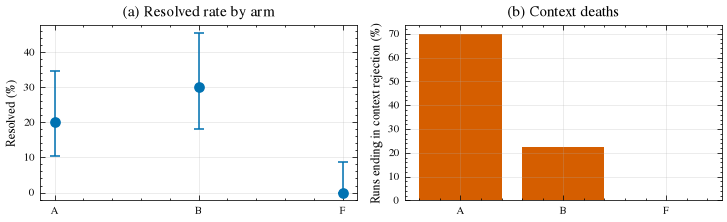

In [9]:
fig, (ax1, ax2) = plotting.figure("double", aspect=0.32, ncols=2)
s = summary.sort("arm")
cis = [stats.wilson_ci(int(r["resolved"] * r["n"] + 0.5), r["n"]) for r in s.iter_rows(named=True)]
ax1.errorbar(
    s["arm"].to_list(),
    [c.point * 100 for c in cis],
    fmt="o",
    capsize=3,
    yerr=[[(c.point - c.lo) * 100 for c in cis], [(c.hi - c.point) * 100 for c in cis]],
)
ax1.set(ylabel="Resolved (%)", title="(a) Resolved rate by arm")
ax2.bar(s["arm"].to_list(), (s["context_death"] * 100).to_list(), color=plotting.PALETTE[3])
ax2.set(ylabel="Runs ending in context rejection (%)", title="(b) Context deaths")
fig.tight_layout()
suffix = f"_{P.label}" if P.label else ""
plotting.save_fig(fig, f"e1b_context_fixes{suffix}", exp_dir=EXP_DIR, run=run)

## 8 · Teardown

In [10]:
tables = EXP_DIR / "tables"
tables.mkdir(exist_ok=True)
summary.write_csv(tables / f"e1b_arms{suffix}.csv")
comparisons.write_csv(tables / f"e1b_comparisons{suffix}.csv")
run.finish()
print((run.dir / "summary.json").read_text())

🏃 View run 20260926T234243Z-f77eec3d-d931 at: http://127.0.0.1:5000/#/experiments/4/runs/e3c1a05cf5bb4263956742cdfbfcd090
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4
{
  "run_id": "20260926T234243Z-f77eec3d-d931",
  "status": "FINISHED",
  "wall_s": 40.334,
  "monitor_overhead_s": {
    "gpu": 0.484,
    "host": 0.297,
    "containers": 0.06,
    "vllm": 0.311
  },
  "gpu_energy_kwh": 0.00019885222222222222,
  "codecarbon": {
    "energy_kwh": 0.0004825005273692777,
    "emissions_kg": 0.00034423565874686486,
    "cpu_kwh": 0.00011375173221889434,
    "gpu_kwh": 0.00017974653268382212,
    "ram_kwh": 0.00018900226246656128,
    "region": "IND"
  }
}
